In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)


In [ ]:
df= pd.read_csv('https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/mobile_price.csv')


In [ ]:
df.head()


,Product_id,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
0,203,2357,10,135.0,5.2,424,8,1.35,16.0,3.000,13.00,8.0,2610,7.4
1,880,1749,10,125.0,4.0,233,2,1.30,4.0,1.000,3.15,0.0,1700,9.9
2,40,1916,10,110.0,4.7,312,4,1.20,8.0,1.500,13.00,5.0,2000,7.6
3,99,1315,11,118.5,4.0,233,2,1.30,4.0,0.512,3.15,0.0,1400,11.0
4,880,1749,11,125.0,4.0,233,2,1.30,4.0,1.000,3.15,0.0,1700,9.9


In [ ]:
df.tail()


,Product_id,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
156,1206,3551,4638,178.0,5.46,538,4,1.875,128.0,6.0,12.0,16.0,4080,8.4
157,1296,3211,8016,170.0,5.50,534,4,1.975,128.0,6.0,20.0,8.0,3400,7.9
158,856,3260,8809,150.0,5.50,401,8,2.200,64.0,4.0,20.0,20.0,3000,6.8
159,1296,3211,8946,170.0,5.50,534,4,1.975,128.0,6.0,20.0,8.0,3400,7.9
160,1131,2536,9807,202.0,6.00,367,8,1.500,16.0,3.0,21.5,16.0,2700,8.4


In [ ]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Product_id    161 non-null    int64  
 1   Price         161 non-null    int64  
 2   Sale          161 non-null    int64  
 3   weight        161 non-null    float64
 4   resoloution   161 non-null    float64
 5   ppi           161 non-null    int64  
 6   cpu core      161 non-null    int64  
 7   cpu freq      161 non-null    float64
 8   internal mem  161 non-null    float64
 9   ram           161 non-null    float64
 10  RearCam       161 non-null    float64
 11  Front_Cam     161 non-null    float64
 12  battery       161 non-null    int64  
 13  thickness     161 non-null    float64
dtypes: float64(8), int64(6)
memory usage: 17.7 KB


In [ ]:
df.describe()


,Product_id,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
count,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000
mean,675.559006,2215.596273,621.465839,170.426087,5.209938,335.055901,4.857143,1.502832,24.501714,2.204994,10.378261,4.503106,2842.111801,8.921739
std,410.851583,768.187171,1546.618517,92.888612,1.509953,134.826659,2.444016,0.599783,28.804773,1.609831,6.181585,4.342053,1366.990838,2.192564
min,10.000000,614.000000,10.000000,66.000000,1.400000,121.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,800.000000,5.100000
25%,237.000000,1734.000000,37.000000,134.100000,4.800000,233.000000,4.000000,1.200000,8.000000,1.000000,5.000000,0.000000,2040.000000,7.600000
50%,774.000000,2258.000000,106.000000,153.000000,5.150000,294.000000,4.000000,1.400000,16.000000,2.000000,12.000000,5.000000,2800.000000,8.400000
75%,1026.000000,2744.000000,382.000000,170.000000,5.500000,428.000000,8.000000,1.875000,32.000000,3.000000,16.000000,8.000000,3240.000000,9.800000
max,1339.000000,4361.000000,9807.000000,753.000000,12.200000,806.000000,8.000000,2.700000,128.000000,6.000000,23.000000,20.000000,9500.000000,18.500000


In [ ]:
df.shape


(161, 14)

In [ ]:
df.isnull().sum()


Product_id      0
Price           0
Sale            0
weight          0
resoloution     0
ppi             0
cpu core        0
cpu freq        0
internal mem    0
ram             0
RearCam         0
Front_Cam       0
battery         0
thickness       0
dtype: int64

In [ ]:
#statistical Summary
print("Statistical Summary")
summary = df.agg(['mean','median','std','min','max']).T
print(summary)


Statistical Summary
                     mean   median          std    min     max
Product_id     675.559006   774.00   410.851583   10.0  1339.0
Price         2215.596273  2258.00   768.187171  614.0  4361.0
Sale           621.465839   106.00  1546.618517   10.0  9807.0
weight         170.426087   153.00    92.888612   66.0   753.0
resoloution      5.209938     5.15     1.509953    1.4    12.2
ppi            335.055901   294.00   134.826659  121.0   806.0
cpu core         4.857143     4.00     2.444016    0.0     8.0
cpu freq         1.502832     1.40     0.599783    0.0     2.7
internal mem    24.501714    16.00    28.804773    0.0   128.0
ram              2.204994     2.00     1.609831    0.0     6.0
RearCam         10.378261    12.00     6.181585    0.0    23.0
Front_Cam        4.503106     5.00     4.342053    0.0    20.0
battery       2842.111801  2800.00  1366.990838  800.0  9500.0
thickness        8.921739     8.40     2.192564    5.1    18.5


In [ ]:
corr_matrix=df.corr()
corr_matrix


,Product_id,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
Product_id,1.000000,0.165136,0.218548,0.035869,-0.017817,0.207271,-0.008634,0.092428,0.261186,0.236194,0.172812,0.071020,0.031745,0.039807
Price,0.165136,1.000000,0.273263,0.144555,0.404010,0.817614,0.686811,0.727383,0.776738,0.896915,0.739538,0.675286,0.559946,-0.716773
Sale,0.218548,0.273263,1.000000,0.016114,0.017154,0.235896,0.069517,0.099133,0.489308,0.373127,0.292164,0.437233,0.120338,-0.047991
weight,0.035869,0.144555,0.016114,1.000000,0.890416,-0.054683,0.216257,0.222730,0.098849,0.149283,-0.029448,-0.005971,0.833783,-0.185262
resoloution,-0.017817,0.404010,0.017154,0.890416,1.000000,0.181292,0.472226,0.505454,0.202660,0.327216,0.249892,0.202720,0.843462,-0.533708
ppi,0.207271,0.817614,0.235896,-0.054683,0.181292,1.000000,0.487990,0.713168,0.618560,0.748724,0.774008,0.491371,0.302517,-0.496791
cpu core,-0.008634,0.686811,0.069517,0.216257,0.472226,0.487990,1.000000,0.491519,0.276251,0.483128,0.611353,0.586698,0.459728,-0.697935
cpu freq,0.092428,0.727383,0.099133,0.222730,0.505454,0.713168,0.491519,1.000000,0.441400,0.633547,0.625104,0.358319,0.473137,-0.614458
internal mem,0.261186,0.776738,0.489308,0.098849,0.202660,0.618560,0.276251,0.441400,1.000000,0.875354,0.451917,0.555733,0.461506,-0.367412
ram,0.236194,0.896915,0.373127,0.149283,0.327216,0.748724,0.483128,0.633547,0.875354,1.000000,0.648073,0.647470,0.541001,-0.521074


In [ ]:
price_corr = corr_matrix[['Price']].sort_values(by='Price',ascending=False)#finding the correlation of featuers against Price column. Sorting in descending order.
price_corr


,Price
Price,1.000000
ram,0.896915
ppi,0.817614
internal mem,0.776738
RearCam,0.739538
cpu freq,0.727383
cpu core,0.686811
Front_Cam,0.675286
battery,0.559946
resoloution,0.404010


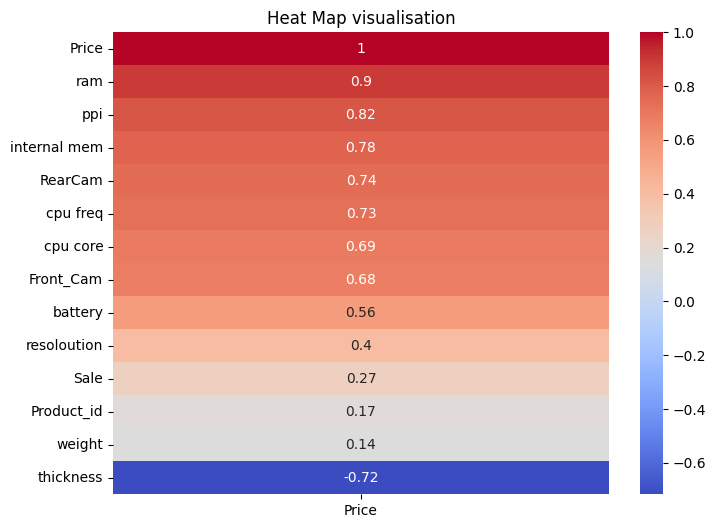

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(data=price_corr,cmap='coolwarm',annot=True)
plt.title("Heat Map visualisation")
plt.show()


The top 4 features most related with Price are 

ram - r as 0.9 

ppi - r as 0.82

internal mem - r as 0.78

RearCam = r as 0.74

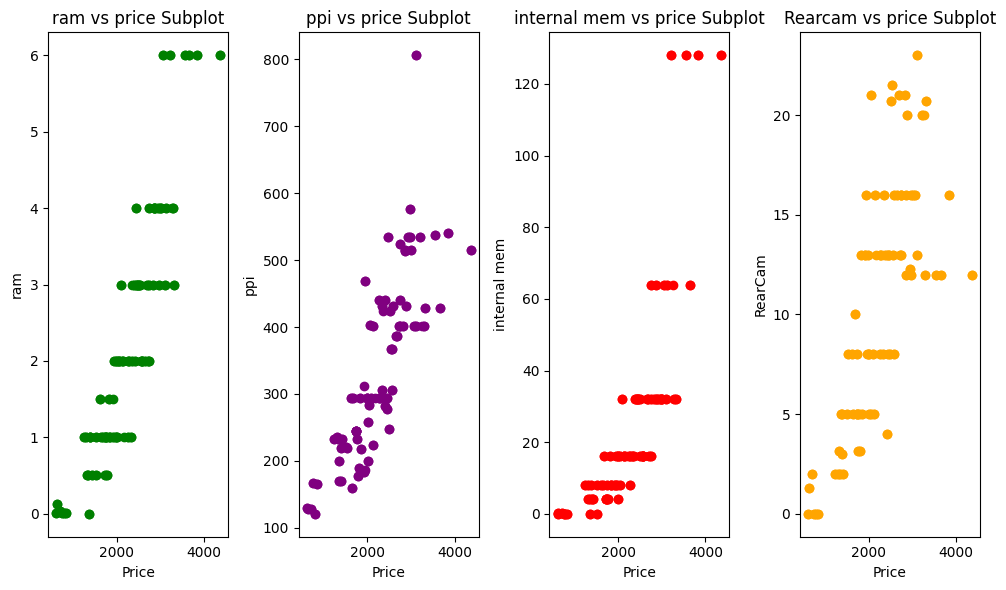

In [ ]:
#scatterplots

x = df['Price']
y1 = df['ram']
y2 = df['ppi']
y3 = df['internal mem']
y4 = df['RearCam']

# Create a grid with 1 row and 2 columns of charts
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(10, 6))

# Plot on the first grid item
ax1.scatter(x, y1, color='green')
ax1.set_title('ram vs price Subplot')
ax1.set_xlabel('Price')
ax1.set_ylabel('ram')

# Plot on the second grid item
ax2.scatter(x, y2, color='purple')
ax2.set_title('ppi vs price Subplot')
ax2.set_xlabel('Price')
ax2.set_ylabel('ppi')

# Plot on the second grid item
ax3.scatter(x, y3, color='red')
ax3.set_title('internal mem vs price Subplot')
ax3.set_xlabel('Price')
ax3.set_ylabel('internal mem')

# Plot on the second grid item
ax4.scatter(x, y4, color='orange')
ax4.set_title('Rearcam vs price Subplot')
ax4.set_xlabel('Price')
ax4.set_ylabel('RearCam')

# Adjust layout spacing and draw
plt.tight_layout()
plt.show()


All the 4 feature has positive linear relationship with the Price variable.

In [14]:
#Feature Selection
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression
X=df.drop(labels=['Price','Product_id'],axis=1)
y=df['Price']#target
selector=SelectKBest(score_func=f_regression,k=5)
X_new = selector.fit_transform(X,y)
X_new.shape


(161, 5)

In [ ]:
#view the selected columns
selected_cols= X.columns[selector.get_support()]
print(selected_cols)


Index(['ppi', 'cpu freq', 'internal mem', 'ram', 'RearCam'], dtype='str')


In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_new,y,test_size=0.2,random_state=42)


In [ ]:
#Linear Regression model

from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)
my_slope=model.coef_
my_intercept=model.intercept_
print(f" Slope : {my_slope}, Intercept : {my_intercept}")


 Slope : [  0.84844408 290.67146818   2.5702236  212.69804481  19.67157969], Intercept : 766.2131400402207


In [ ]:
y_pred=model.predict(X_test)


In [ ]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
r2=r2_score(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
root_mse = mean_squared_error(y_test,y_pred)**0.5
print(f"r2score: {r2}")
print(f"mean absolute error: {mae}")
print(f"mean squared error: {mse}")
print(f"root mean squared error: {root_mse}")


r2score: 0.828018588789879
mean absolute error: 261.4829577582868
mean squared error: 97494.37543105223
root mean squared error: 312.24089327160885


In [20]:
result_residual = y_test-y_pred
result_residual


105    -75.756442
108   -138.998881
142   -431.051513
55     264.350713
94     -19.346130
29     256.622437
101    -75.756442
51     -99.846995
100   -297.684596
143   -431.051513
19    -347.309366
84      63.612313
15    -249.442955
66    -163.385029
24    -628.342013
30    -273.171560
128    172.432895
148   -351.876074
98    -149.747282
16    -273.171560
75     102.086894
18    -249.442955
12     270.919233
9      -60.684596
31    -116.408043
152    749.792949
97     268.016183
56     139.766160
132   -514.167069
104    459.867187
137    302.536555
78     492.904098
60     139.388974
Name: Price, dtype: float64

The r2 score of 0.828 indicates that the model explains approximately 82.8% of the variability in mobile phone prices, suggesting a strong relationship between the selected features and the target variable."

The model produced a Mean Absolute Error (MAE) of 261.48, which means that, on average, the predicted mobile price differs from the actual price by about ₹261.
Considering that the average mobile price in the dataset is approximately ₹2216, the prediction error is relatively small and acceptable.

The Root Mean Squared Error (RMSE) of 312.24 is only moderately higher than the MAE, indicating that the model does not make a large number of extreme prediction errors. The Mean Squared Error (MSE) of 97,494.38 further confirms that the overall prediction error remains within a reasonable range.

Overall, the model demonstrates good predictive performance and is capable of accurately estimating mobile prices based on the selected features. However, there is still approximately 17.2% unexplained variation in the target variable, suggesting that additional features or more advanced regression techniques could potentially improve prediction accuracy. Therefore, while the current model is satisfactory for predicting mobile prices, there remains scope for further enhancement.